In [7]:
from google.colab import files

uploaded = files.upload()

Saving spam_sms.csv to spam_sms (1).csv


In [8]:
import pandas as pd

df = pd.read_csv("spam_sms.csv", encoding="latin-1")

df.head()

,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [9]:
df = df.sample(n=2000, random_state=42)

In [12]:
import os

print(os.listdir())

['.config', 'spam_sms.csv', 'spam_sms (1).csv', 'sample_data']


In [14]:
print(df.columns)
print(df.info())

Index(['v1', 'v2'], dtype='object')
<class 'pandas.core.frame.DataFrame'>
Index: 2000 entries, 3245 to 1609
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   v1      2000 non-null   object
 1   v2      2000 non-null   object
dtypes: object(2)
memory usage: 46.9+ KB
None


In [15]:
print(df.columns)
print(df.shape)

Index(['v1', 'v2'], dtype='object')
(2000, 2)


In [16]:
df = df[['v1', 'v2']]

df.columns = ['label', 'message']

df.head()

,label,message
3245,ham,"Funny fact Nobody teaches volcanoes 2 erupt, t..."
944,ham,I sent my scores to sophas and i had to do sec...
1044,spam,We know someone who you know that fancies you....
2484,ham,Only if you promise your getting out as SOON a...
812,spam,Congratulations ur awarded either Ã¥Â£500 of C...


In [17]:
print(df.isnull().sum())

label      0
message    0
dtype: int64


In [18]:
df = df.dropna()

In [19]:
df['label'] = df['label'].map({'ham': 0, 'spam': 1})

print(df['label'].value_counts())

label
0    1728
1     272
Name: count, dtype: int64


In [20]:
print(df['label'].value_counts())

label
0    1728
1     272
Name: count, dtype: int64


In [22]:
print(df.isnull().sum())

label      0
message    0
dtype: int64


In [23]:
df['label'] = df['label'].map({'ham': 0, 'spam': 1})

print(df['label'].value_counts())

Series([], Name: count, dtype: int64)


In [25]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['message'] = df['message'].apply(clean_text)

df.head()

,label,message
3245,NaN,funny fact nobody teaches volcanoes erupt tsun...
944,NaN,i sent my scores to sophas and i had to do sec...
1044,NaN,we know someone who you know that fancies you ...
2484,NaN,only if you promise your getting out as soon a...
812,NaN,congratulations ur awarded either of cd gift v...


In [26]:
X = df['message'].values
y = df['label'].values

In [31]:
from sklearn.model_selection import train_test_split
import numpy as np

# Restore 'label' values because mapping was run multiple times resulting in NaNs
# 'ham' -> 0, 'spam' -> 1
# We will reload the original v1 column from the dataframe context if needed, or simply map it from the original file or state.
import pandas as pd
df_temp = pd.read_csv('spam_sms.csv', encoding='latin-1')
df_temp = df_temp.loc[df.index] # Keep the exact same sampled indices
df['label'] = df_temp['v1'].map({'ham': 0, 'spam': 1})

# Update X and y after restoring the labels
X = df['message'].values
y = df['label'].values.astype(int)

# Perform the train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 1600
Testing samples: 400


In [32]:
from tensorflow.keras.preprocessing.text import Tokenizer

tokenizer = Tokenizer(num_words=5000, oov_token="<OOV>")

tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

In [33]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

max_len = 50

X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=max_len,
    padding='post'
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=max_len,
    padding='post'
)

print(X_train_pad.shape)
print(X_test_pad.shape)

(1600, 50)
(400, 50)


In [34]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

model = Sequential([
    Embedding(input_dim=5000, output_dim=64, input_length=50),
    LSTM(64),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [35]:
X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=max_len,
    padding='post'
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=max_len,
    padding='post'
)

print(X_train_pad.shape)
print(X_test_pad.shape)

(1600, 50)
(400, 50)


In [36]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

model = Sequential([
    Embedding(input_dim=5000, output_dim=64, input_length=50),
    LSTM(64),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [37]:
history = model.fit(
    X_train_pad,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - accuracy: 0.8664 - loss: 0.4459 - val_accuracy: 0.8500 - val_loss: 0.4305
Epoch 2/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.8672 - loss: 0.4045 - val_accuracy: 0.8500 - val_loss: 0.4387
Epoch 3/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.8672 - loss: 0.4026 - val_accuracy: 0.8500 - val_loss: 0.4109
Epoch 4/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.9430 - loss: 0.2122 - val_accuracy: 0.9219 - val_loss: 0.3259
Epoch 5/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - accuracy: 0.9750 - loss: 0.1246 - val_accuracy: 0.9563 - val_loss: 0.1876
Epoch 6/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - accuracy: 0.9797 - loss: 0.1061 - val_accuracy: 0.9563 - val_loss: 0.1940
Epoch 7/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.9812 - loss: 0.0937 - val_accuracy: 0.9563 - val_loss: 0.1927
Epoch 8/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.9812 - loss: 0.0946 - val_accuracy: 0.9625 - v

In [38]:
loss, accuracy = model.evaluate(X_test_pad, y_test)

print("Test Accuracy:", accuracy)

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9625 - loss: 0.1739
Test Accuracy: 0.9624999761581421


In [39]:
import numpy as np

y_prob = model.predict(X_test_pad)

y_pred = (y_prob > 0.5).astype(int).flatten()

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step


In [40]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1-Score :", f1)

Accuracy : 0.9625
Precision: 0.9333333333333333
Recall   : 0.7777777777777778
F1-Score : 0.8484848484848485


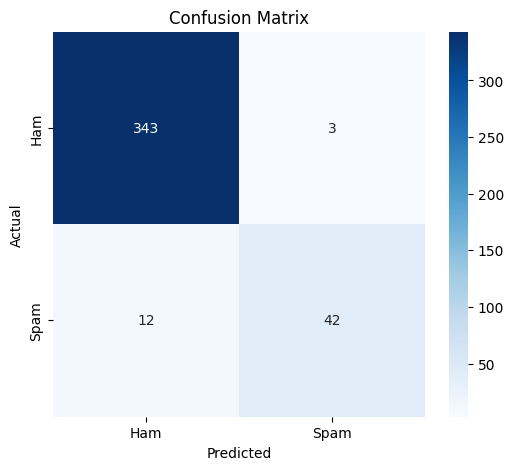

In [41]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [42]:
def predict_sms(message):
    cleaned = clean_text(message)

    sequence = tokenizer.texts_to_sequences([cleaned])

    padded = pad_sequences(
        sequence,
        maxlen=50,
        padding='post'
    )

    prediction = model.predict(padded, verbose=0)[0][0]

    if prediction > 0.5:
        print("SMS:", message)
        print("Prediction: SPAM")
        print("Probability:", round(float(prediction), 4))
    else:
        print("SMS:", message)
        print("Prediction: HAM")
        print("Probability:", round(float(1 - prediction), 4))

In [43]:
predict_sms("Congratulations! You have won a free prize. Click now!")

SMS: Congratulations! You have won a free prize. Click now!
Prediction: SPAM
Probability: 0.9889


In [44]:
predict_sms("Your account has been selected for a cash reward. Claim now!")

SMS: Your account has been selected for a cash reward. Claim now!
Prediction: SPAM
Probability: 0.9889
